# Drude particle displacement statistics

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mdtraj

In [2]:
trj = mdtraj.load('../pol/traj.dcd', top='../pol/config-p.pdb')
print(trj)

dcdplugin) detected standard 32-bit DCD file of native endianness
dcdplugin) CHARMM format DCD file (also NAMD 2.1 and later)
<mdtraj.Trajectory with 2000 frames, 17100 atoms, 600 residues, and unitcells>


In [3]:
def drudedist(trj):
    """Statistics of distances between Drude particles and cores"""

    atoms, bonds = trj.topology.to_dataframe()
    res = pd.unique(atoms['resName'])
    
    mols = pd.DataFrame(index=res, columns=['natoms', 'nmols'])
    for spec in res:
        #mols[spec] = trj.topology.select(f"resname {spec}")
        moli = atoms.query(f"resName == '{spec}'").index
        i = moli[0]
        j = moli[-1]
        nmols = atoms.iloc[j].resSeq - atoms.iloc[i].resSeq + 1
        natoms = int((j - i + 1) / nmols)
        mols.loc[spec] = [natoms, nmols]
    print(mols)

    for mol in res:
        print('')
        print(mol)

        atnames = []
        offset = atoms.query(f"resName == '{mol}'").index[0]
        for i in range(offset, offset + mols['natoms'][mol] - 1):
            if atoms['name'][i+1] == 'D' + atoms['name'][i]:
                atnames.append(atoms['name'][i])
        n = len(atnames)

        pairlist = []
        pairnames = []
        for i in range(len(atoms) - 1):
            if atoms['resName'][i] == mol and atoms['name'][i+1] == 'D' + atoms['name'][i]:
                pairlist.append([i, i+1])
                pairnames.append([atoms['name'][i], atoms['name'][i+1]])
        pairs = np.array(pairlist)
        
        dist = mdtraj.compute_distances(trj, pairs).T

        a = []
        for i in range(0, len(dist), n):
            a.append(dist[i:i+n])
        moldist = np.concatenate(a, axis=1)

        ddist = pd.DataFrame(moldist.T, columns=atnames)
        pd.set_option("display.float_format", "{:,.4f}".format)
        stat = ddist.describe(percentiles=[]).loc[['mean', 'min', 'max']]
        print(stat)

        ddist.boxplot()
        plt.title(mol)
        plt.ylabel("d / nm")
        plt.ylim(0, 0.02)
        plt.show()

    natoms nmols
c2c     27   300
tf2     30   300

c2c
         N1     C1     N2     C2     C3     C4     C5     C6
mean 0.0029 0.0026 0.0022 0.0023 0.0021 0.0034 0.0019 0.0018
min  0.0000 0.0000 0.0000 0.0000 0.0000 0.0000 0.0000 0.0000
max  0.0162 0.0164 0.0132 0.0117 0.0145 0.0108 0.0072 0.0072


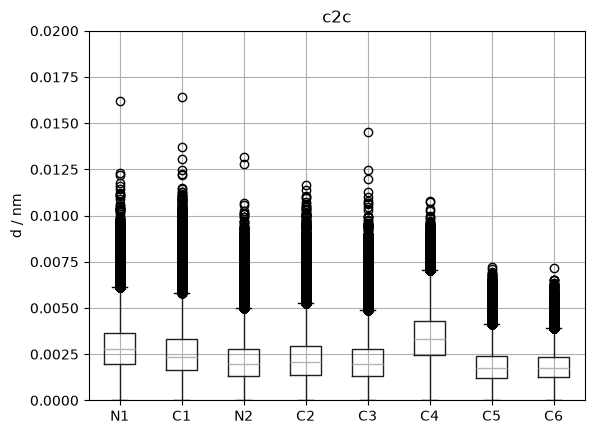


tf2
         C1     F1     F2     F3     S1      N     O1     O2     S2     O3  \
mean 0.0018 0.0021 0.0021 0.0021 0.0044 0.0035 0.0030 0.0030 0.0044 0.0031   
min  0.0000 0.0000 0.0000 0.0000 0.0005 0.0000 0.0000 0.0000 0.0005 0.0000   
max  0.0049 0.0055 0.0054 0.0056 0.0088 0.0079 0.0085 0.0089 0.0092 0.0086   

         O4     C2     F4     F5     F6  
mean 0.0030 0.0018 0.0021 0.0021 0.0021  
min  0.0000 0.0000 0.0001 0.0000 0.0001  
max  0.0090 0.0050 0.0056 0.0056 0.0053  


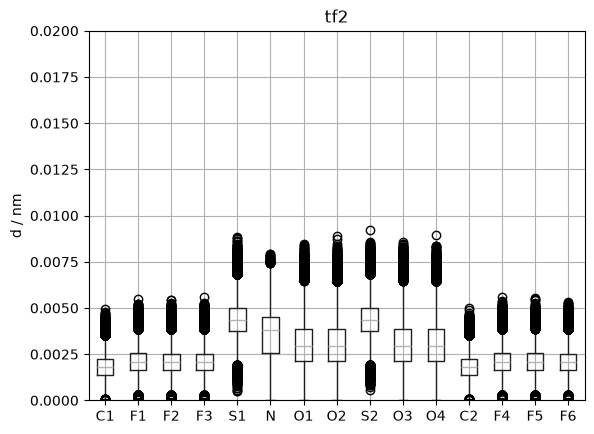

In [4]:
drudedist(trj)